# DSAA2011 Project 2: sharp guarantees under dependence

This notebook reproduces the report using the implementations in `experiments/verify.py`.
Run from the repository root. Install `requirements.txt` first.

The formulas are population moment bounds. The proofs are in `report.tex`; reading and derivation notes are in `notes/`. These results are presented as an elementary specialization of classical discrete moment bounds, not a claim of literature priority.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "experiments/verify.py").exists():
    raise RuntimeError("Run this notebook from the DSAAproject repository root.")
sys.path.insert(0, str(ROOT / "experiments"))
from verify import interval, threshold, witness, verify, outputs
import numpy as np


## 1. The three-voter ambiguity
All pairs are independent when p=0.6 and rho=0, but the full triple need not be independent.


In [2]:
p, k = .6, 3
bounds = interval(k, p, 0.)
q = witness(k, k*p, k*(k-1)*p*p)
print("Attainable accuracy interval:", bounds)
print("Attaining count probabilities:", np.round(q, 6))
assert np.allclose(bounds, [.52, .84])
assert np.allclose(q, [0, .48, .24, .28])


Attainable accuracy interval: (0.5199999999999996, 0.8399999999999999)
Attaining count probabilities: [0.   0.48 0.24 0.28]


## 2. The sharp strict-benefit threshold
A boundary distribution supported on at most three counts attains A=p. Uniformly choose which classifiers are correct conditional on the count to obtain the binary joint law.


In [3]:
k, p = 7, .6
rho_star, nu_star, q = threshold(k, p)
s = np.arange(k+1)
print("Critical correlation:", rho_star)
print("Support and probabilities:", [(int(i), float(q[i])) for i in s if q[i] > 1e-10])
print("Accuracy at threshold:", q @ (s > k//2))
print("Mean:", q @ s, "factorial second moment:", q @ (s*(s-1)))


Critical correlation: -0.07142857142857137
Support and probabilities: [(3, 0.4), (5, 0.6)]
Accuracy at threshold: 0.6
Mean: 4.2 factorial second moment: 14.4


## 3. Independent verification against linear programs
The count LP and full binary LP do not use the analytic formula as an input constraint. The full run checks lower/upper endpoints, pointwise certificates, feasible witnesses, threshold boundaries, and infeasible inputs.


In [4]:
summary = verify()
outputs(summary)


{
  "certificate_values": 2576,
  "count_lp_cases": 702,
  "binary_lp_cases": 41,
  "threshold_cases": 720,
  "rejected_infeasible": 36,
  "max_absolute_lp_gap": 2.55351295663786e-14,
  "seed": 20261013
}
K=  3: [0.520000, 0.840000], rho*=-0.111111
K=  5: [0.466667, 0.920000], rho*=-0.083333
K=  7: [0.480000, 0.960000], rho*=-0.071429
K= 11: [0.500000, 1.000000], rho*=-0.030303
K= 21: [0.580000, 1.000000], rho*=-0.003968
K= 23: [0.592000, 1.000000], rho*=-0.001318
K= 25: [0.600000, 1.000000], rho*=0.000000
K= 27: [0.616000, 1.000000], rho*=0.002849
K= 31: [0.640000, 1.000000], rho*=0.005376
K= 51: [0.721429, 1.000000], rho*=0.014379
K=101: [0.823077, 1.000000], rho*=0.020957


## 4. Exact finite-size consequence
For p=3/5 and rho=0, odd K=25 has no strict guaranteed gain; K=27 is the first strict gain. The report proves this algebraically for all odd K, rather than inferring it from a scan.


In [5]:
for k in [3, 5, 23, 25, 27, 31]:
    lo, hi = interval(k, .6, 0.)
    print(f"K={k}: [{lo:.6f}, {hi:.6f}]")
assert abs(interval(25, .6, 0.)[0] - .6) < 1e-12
assert interval(27, .6, 0.)[0] > .6


K=3: [0.520000, 0.840000]
K=5: [0.466667, 0.920000]
K=23: [0.592000, 1.000000]
K=25: [0.600000, 1.000000]
K=27: [0.616000, 1.000000]
K=31: [0.640000, 1.000000]


## 5. Rebuild the figures
The comparison includes both the original C-bound and Cantelli applied to the correct integer failure threshold. This separates the threshold correction from the lattice correction.


Generated bounds and moment polygon figures.


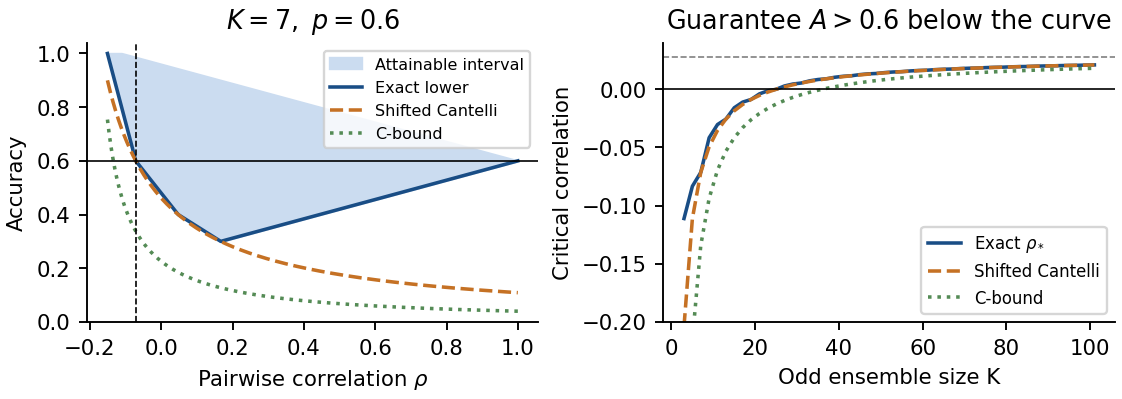

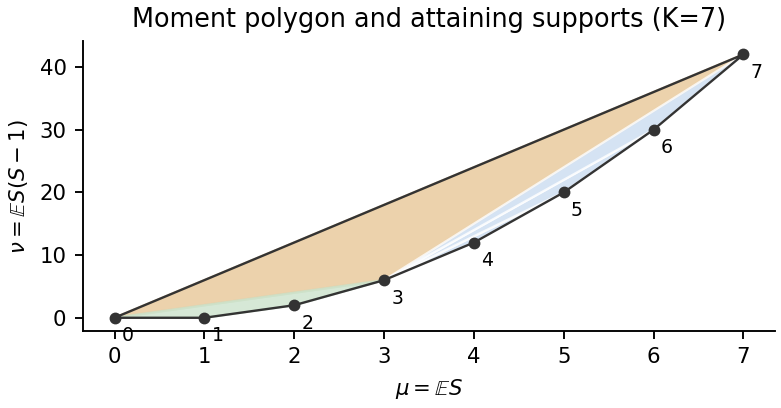

In [6]:
import runpy
runpy.run_path(str(ROOT / "experiments/plot.py"), run_name="__main__")
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures/bounds.png")))
display(Image(filename=str(ROOT / "figures/moment_polygon.png")))


## Submission notes
Replace the report and presentation authorship placeholders with the actual team. Rename this notebook and `requirements.txt` using the assigned GroupID as specified in `Requirements.md`. Complete accurate individual contribution statements and review the AI-use statement. The mathematical guarantees here do not account for moment estimation error.
